# Leave-generator-out (unseen-LLM) experiment
**Question:** does a detector trained on essays from some LLMs still work on essays from LLMs it has *never seen*?

For each fold, whole generator families are removed from training/validation and used only for testing. Both TF-IDF+LR and BERT are trained on identical data.
- **Seen test:** AI essays from training generators (held out essays) + held-out human essays
- **Unseen test:** AI essays from the held-out generator family + the same held-out human essays

Run with GPU + Internet ON, then **Save Version -> Save & Run All (Commit)**. Expect about 45-60 minutes.
Set `SMOKE_TEST = True` first to check that it runs (a few minutes).

In [14]:
import os, re, random, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, precision_score, recall_score

SMOKE_TEST = False        # <-- set to False for the real run
RUN_BERT   = True
EXTERNAL_CSV = "/kaggle/input/datasets/thedrcat/daigt-v2-train-dataset/train_v2_drcat_02.csv"
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:",device)
OUT_DIR="/kaggle/working/results_logo" if os.path.exists("/kaggle/working") else "./results_logo"; os.makedirs(OUT_DIR,exist_ok=True)
MAX_LEN=512; BATCH_SIZE=8; EPOCHS=2; LR=2e-5
if SMOKE_TEST: N_TEST,N_TR,N_VA,EPOCHS = 30,60,20,1
else:          N_TEST,N_TR,N_VA = 750,2000,250

device: cuda


## 1. Load data and define generator families

In [15]:
raw=pd.read_csv(EXTERNAL_CSV)
if "generated" not in raw.columns: raw=raw.rename(columns={"label":"generated"})
raw=raw[["text","generated","source"]].dropna().drop_duplicates(subset="text")
raw["text"]=raw.text.astype(str).str.replace(r"\s+"," ",regex=True).str.strip()
# 3 AI essays inside 'train_essays' have an unknown generator -> drop them
raw=raw[~((raw.source=="train_essays")&(raw.generated==1))].reset_index(drop=True)

# generator family of each AI source (verify against the dataset page). Unlisted sources -> 'other' (always seen in training)
FAMILY={"mistral7binstruct_v1":"mistral","mistral7binstruct_v2":"mistral","mistralai/Mistral-7B-Instruct-v0.1":"mistral",
        "llama2_chat":"llama","llama_70b_v1":"llama","NousResearch/Llama-2-7b-chat-hf":"llama",
        "kingki19_palm":"palm","palm-text-bison1":"palm","falcon_180b_v1":"falcon","cohere-command":"cohere"}
raw["family"]=np.where(raw.generated==1, raw.source.map(FAMILY).fillna("other"), "human")
print(raw.groupby(["generated","family"]).size())

FOLDS={"A_unseen_mistral":["mistral"], "B_unseen_llama":["llama"], "C_unseen_palm_falcon_cohere":["palm","falcon","cohere"]}

generated  family 
0          human      27371
1          cohere       350
           falcon      1055
           llama       3993
           mistral     5242
           other       5121
           palm        1733
dtype: int64


## 2. Fold construction, metrics, models

In [16]:
def make_fold(held):
    ai=raw[raw.generated==1]; hu=raw[raw.generated==0].sample(frac=1,random_state=SEED)
    unseen=ai[ai.family.isin(held)]; seen=ai[~ai.family.isin(held)].sample(frac=1,random_state=SEED)
    k=N_TEST+N_VA
    seen_te,seen_va,seen_tr=seen.iloc[:N_TEST],seen.iloc[N_TEST:k],seen.iloc[k:k+N_TR]
    hu_te,hu_va,hu_tr=hu.iloc[:N_TEST],hu.iloc[N_TEST:k],hu.iloc[k:k+N_TR]
    unseen_te=unseen.sample(min(N_TEST,len(unseen)),random_state=SEED)
    sh=lambda d:d.sample(frac=1,random_state=SEED).reset_index(drop=True)
    return dict(train=sh(pd.concat([seen_tr,hu_tr])), val=sh(pd.concat([seen_va,hu_va])),
                test_seen=sh(pd.concat([seen_te,hu_te])),
                test_unseen=sh(pd.concat([unseen_te,hu_te.iloc[:len(unseen_te)]])))

def score(y,p):
    y=np.array(y); p=np.array(p); yh=(p>=0.5).astype(int)
    return dict(auc=roc_auc_score(y,p),acc=accuracy_score(y,yh),precision=precision_score(y,yh,zero_division=0),
                recall=recall_score(y,yh,zero_division=0),f1=f1_score(y,yh,zero_division=0),
                specificity=float(((yh==0)&(y==0)).sum()/max((y==0).sum(),1)))

def run_tfidf(F):
    vec=TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True,max_features=50000)
    lr=LogisticRegression(max_iter=1000).fit(vec.fit_transform(F["train"].text),F["train"].generated)
    return {k:lr.predict_proba(vec.transform(F[k].text))[:,1] for k in ["test_seen","test_unseen"]}

def run_bert(F):
    from transformers import BertTokenizerFast, BertForSequenceClassification, get_linear_schedule_with_warmup
    from torch.utils.data import DataLoader, TensorDataset
    tok=BertTokenizerFast.from_pretrained("bert-base-uncased")
    def dl(d,shuffle):
        e=tok(list(d.text),padding="max_length",truncation=True,max_length=MAX_LEN,return_tensors="pt")
        return DataLoader(TensorDataset(e["input_ids"],e["attention_mask"],torch.tensor(d.generated.values)),batch_size=BATCH_SIZE,shuffle=shuffle)
    trl,val=dl(F["train"],True),dl(F["val"],False)
    model=BertForSequenceClassification.from_pretrained("bert-base-uncased",num_labels=2).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=0.01)
    steps=len(trl)*EPOCHS; sch=get_linear_schedule_with_warmup(opt,int(.1*steps),steps)
    @torch.no_grad()
    def proba(loader):
        model.eval(); P=[]
        for ii,am,_ in loader: P+=torch.softmax(model(input_ids=ii.to(device),attention_mask=am.to(device)).logits,1)[:,1].cpu().tolist()
        return np.array(P)
    best,best_state=-1,None
    from tqdm.auto import tqdm
    for ep in range(EPOCHS):
        model.train()
        for ii,am,y in tqdm(trl,desc=f"epoch {ep+1}"):
            opt.zero_grad(); loss=model(input_ids=ii.to(device),attention_mask=am.to(device),labels=y.to(device)).loss
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step(); sch.step()
        auc=roc_auc_score(F["val"].generated,proba(val)); print(f"  epoch {ep+1} val_auc={auc:.4f}")
        if auc>best: best=auc; best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state)
    out={k:proba(dl(F[k],False)) for k in ["test_seen","test_unseen"]}
    del model,opt; torch.cuda.empty_cache(); return out

## 3. Run all folds

In [17]:
rows=[]; per_source=[]
for name,held in FOLDS.items():
    F=make_fold(held); print(f"\n=== {name} | train={len(F['train'])} val={len(F['val'])} seen-test={len(F['test_seen'])} unseen-test={len(F['test_unseen'])}")
    models={"TF-IDF+LR":run_tfidf(F)}
    if RUN_BERT: models["BERT"]=run_bert(F)
    for mname,P in models.items():
        for tname in ["test_seen","test_unseen"]:
            r=score(F[tname].generated,P[tname]); rows.append(dict(fold=name,model=mname,test=tname.replace("test_",""),**r))
        u=F["test_unseen"].assign(pred=(P["test_unseen"]>=.5).astype(int)); u=u[u.generated==1]
        for s,g in u.groupby("source"): per_source.append(dict(fold=name,model=mname,source=s,n=len(g),recall=g.pred.mean()))
    print(pd.DataFrame(rows).query("fold==@name").round(4).to_string(index=False))
res=pd.DataFrame(rows); res.to_csv(f"{OUT_DIR}/logo_results.csv",index=False)
ps=pd.DataFrame(per_source); ps.to_csv(f"{OUT_DIR}/logo_per_generator_recall.csv",index=False)


=== A_unseen_mistral | train=4000 val=500 seen-test=1500 unseen-test=1500


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

  epoch 1 val_auc=0.9976


epoch 2:   0%|          | 0/500 [00:00<?, ?it/s]

... (9 outputs left out)

epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

  epoch 1 val_auc=0.9962


epoch 2:   0%|          | 0/500 [00:00<?, ?it/s]

  epoch 2 val_auc=0.9983
                       fold     model   test    auc    acc  precision  recall     f1  specificity
C_unseen_palm_falcon_cohere TF-IDF+LR   seen 0.9986 0.9860     0.9932  0.9787 0.9859       0.9933
C_unseen_palm_falcon_cohere TF-IDF+LR unseen 0.9958 0.9107     0.9920  0.8280 0.9026       0.9933
C_unseen_palm_falcon_cohere      BERT   seen 0.9998 0.9933     0.9933  0.9933 0.9933       0.9933
C_unseen_palm_falcon_cohere      BERT unseen 0.9997 0.9933     0.9933  0.9933 0.9933       0.9933


## 4. Summary table and figure for the paper

                                          auc              f1          recall  \
test                                     seen  unseen    seen  unseen    seen   
fold                        model                                               
A_unseen_mistral            BERT       0.9997  0.9950  0.9868  0.9774  0.9973   
                            TF-IDF+LR  0.9991  0.9938  0.9893  0.9811  0.9840   
B_unseen_llama              BERT       0.9971  0.9897  0.9866  0.9264  0.9853   
                            TF-IDF+LR  0.9957  0.9318  0.9818  0.6278  0.9693   
C_unseen_palm_falcon_cohere BERT       0.9998  0.9997  0.9933  0.9933  0.9933   
                            TF-IDF+LR  0.9986  0.9958  0.9859  0.9026  0.9787   

                                              specificity          
test                                   unseen        seen  unseen  
fold                        model                                  
A_unseen_mistral            BERT       0.9787      0.9760  0.9760 

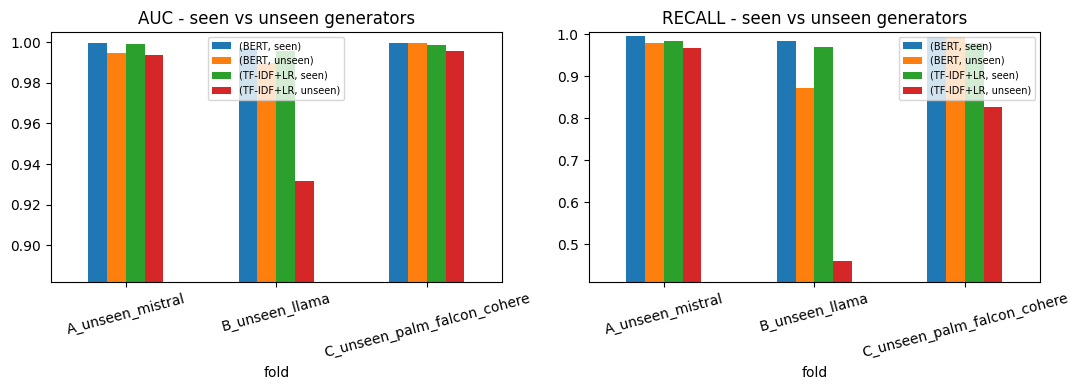

In [18]:


summary=res.pivot_table(index=["fold","model"],columns="test",values=["auc","recall","specificity","f1"]).round(4)
print(summary); summary.to_csv(f"{OUT_DIR}/logo_summary.csv")
print("\nPer-generator recall on UNSEEN generators:"); print(ps.round(4).to_string(index=False))

fig,ax=plt.subplots(1,2,figsize=(11,4))
for a,metric in zip(ax,["auc","recall"]):
    t=res.pivot_table(index="fold",columns=["model","test"],values=metric)
    t.plot(kind="bar",ax=a,rot=15); a.set_title(f"{metric.upper()} - seen vs unseen generators"); a.set_ylim(max(0,t.values.min()-0.05),1.005); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/logo_figure.png",dpi=200); plt.show()

In [20]:
from transformers import BertTokenizerFast, BertForSequenceClassification
import numpy as np
tok = BertTokenizerFast.from_pretrained("bert-base-uncased")
p = next((x for x in [f"{OUT_DIR}/best_model.pt", "/kaggle/working/results/best_model.pt", "./results/best_model.pt"] if os.path.exists(x)), None)
print("checkpoint:", p)
assert p, "no saved model in this session - skip this, the paper is fine without it"
model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2).to(device)
model.load_state_dict(torch.load(p, map_location=device, weights_only=True)); model.eval()
P = []
with torch.no_grad():
    for i in range(0, len(te), 16):
        e = tok(list(te.text.iloc[i:i+16]), padding="max_length", truncation=True, max_length=512, return_tensors="pt")
        P += torch.softmax(model(input_ids=e["input_ids"].to(device), attention_mask=e["attention_mask"].to(device)).logits, 1)[:, 1].cpu().tolist()
out = te.assign(prob_bert=np.array(P))
err = out.loc[lambda d: (d.prob_bert >= .5) != d.generated]
err.to_csv(f"{OUT_DIR}/misclassified_full.csv")
print(len(err), "errors")
for i, r in err.iterrows():
    print(f"#{i} true={'AI' if r.generated else 'human'} P={r.prob_bert:.3f}\n{r.text[:1200]}\n" + "-" * 60)

checkpoint: None


AssertionError: no saved model in this session - skip this, the paper is fine without it